# Error analysis -- best single result (frozen Qwen2.5-3B layer-7 embedding + LR)

No new training here. This reconstructs out-of-fold predictions for the best result found so
far (`decoder_embed_Qwen2.5-3B_L7_mean_lr`, full 5-fold GroupKFold CV, balanced_accuracy=0.3978
-- TRIED.md's layer-depth sweep) from its cached `oof_proba.npy`, then looks at *where* the
errors are: confusion matrix, per-class recall, same-family vs cross-family confusions,
confidence calibration, and concrete misclassified examples.

0.3978 on 18 classes is ~7.2x the random floor (1/18=0.056) -- real signal, but we're still
wrong on the majority of rows. The question this notebook tries to answer: is that because the
*features* are weak, or because many of these 18 classes are genuinely hard to tell apart (e.g.
same-vendor adjacent versions like `claude-opus-4-6`/`4-8`/`5`, or the `gpt-5.6-luna/sol/terra`
triplet)? If errors concentrate in those known-similar clusters rather than spreading evenly,
that's a real ceiling from stylistic overlap, not a fixable modeling gap.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score, confusion_matrix

import sys
sys.path.insert(0, '../src')
from paths import data_dir
from exp_log import EXPERIMENTS_ROOT

## 1. Load data and reconstruct OOF predictions

`experiment_decoder_embedding.py` loads `train.csv` with no shuffling and fills `oof_proba`
at the same row positions GroupKFold assigned as validation -- so re-loading `train.csv` the
same way lines back up with the cached `oof_proba.npy` exactly.

In [2]:
RUN_DIR = EXPERIMENTS_ROOT / "20261103-223628_decoder_embed_Qwen2.5-3B_L7_mean_lr"

df = pd.read_csv(data_dir() / "train.csv")
labels_sorted = sorted(df["model"].unique())

oof_proba = np.load(RUN_DIR / "artifacts" / "oof_proba.npy")
assert not np.isnan(oof_proba).any(), "some rows never got a fold assignment"

df["true_label"] = df["model"]
df["pred_label"] = [labels_sorted[i] for i in oof_proba.argmax(axis=1)]
df["confidence"] = oof_proba.max(axis=1)
df["correct"] = df["true_label"] == df["pred_label"]
df["n_words"] = df["text"].str.split().str.len()

bal_acc = balanced_accuracy_score(df["true_label"], df["pred_label"])
plain_acc = df["correct"].mean()
print(f"balanced accuracy (should match TRIED.md's 0.3978): {bal_acc:.4f}")
print(f"plain accuracy: {plain_acc:.4f}  (close to balanced acc -> classes are ~evenly sized: "
      f"{df['true_label'].value_counts().min()}-{df['true_label'].value_counts().max()} rows/class)")

balanced accuracy (should match TRIED.md's 0.3978): 0.3979
plain accuracy: 0.3979  (close to balanced acc -> classes are ~evenly sized: 149-150 rows/class)


## 2. Confusion matrix

Row-normalized (each row sums to 1) so the diagonal reads directly as per-class recall.

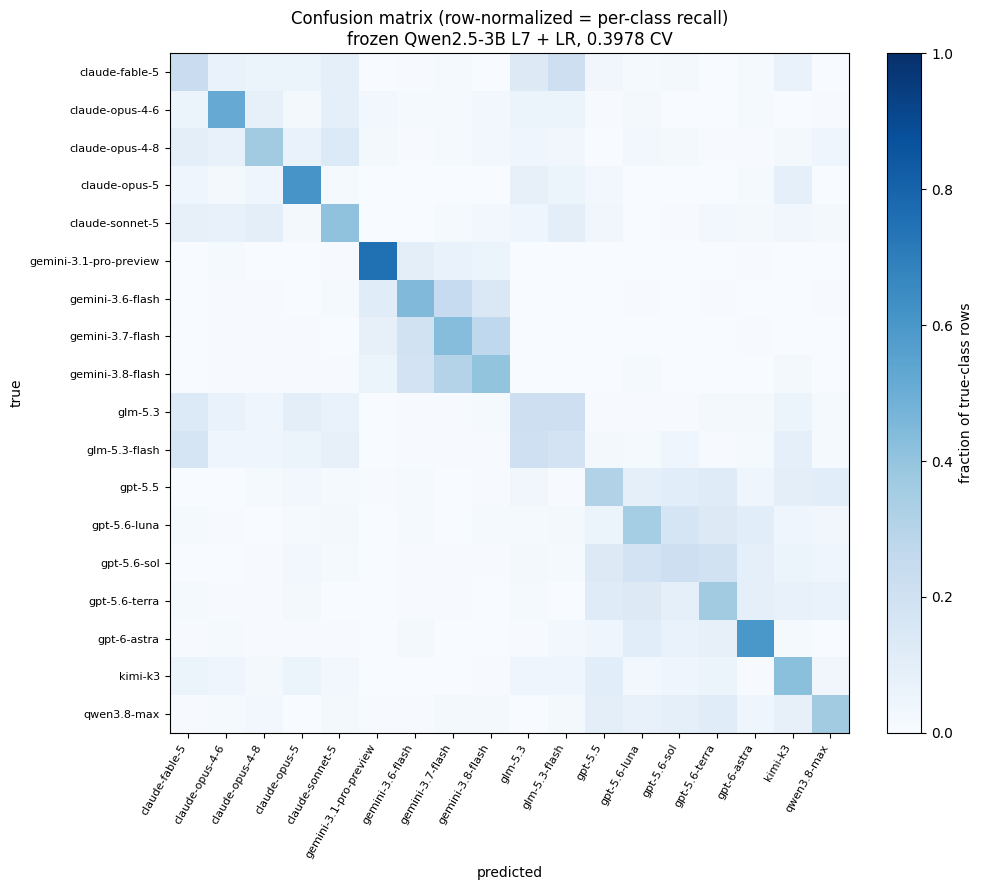

In [3]:
cm = confusion_matrix(df["true_label"], df["pred_label"], labels=labels_sorted)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels_sorted)))
ax.set_yticks(range(len(labels_sorted)))
ax.set_xticklabels(labels_sorted, rotation=60, ha="right", fontsize=8)
ax.set_yticklabels(labels_sorted, fontsize=8)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("Confusion matrix (row-normalized = per-class recall)\nfrozen Qwen2.5-3B L7 + LR, 0.3978 CV")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="fraction of true-class rows")
fig.tight_layout()
plt.show()

## 3. Per-class recall

Which classes does the model actually nail, and which does it barely get above chance?

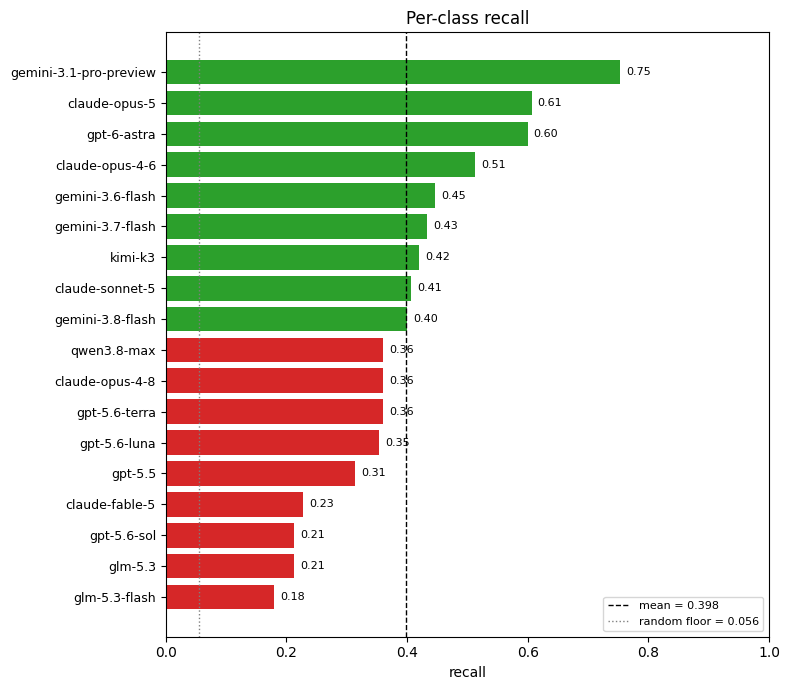

In [4]:
recalls = np.diag(cm_norm)
order = np.argsort(recalls)
labels_by_recall = [labels_sorted[i] for i in order]
recalls_sorted = recalls[order]
mean_recall = recalls.mean()
random_floor = 1 / len(labels_sorted)

fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#d62728" if r < mean_recall else "#2ca02c" for r in recalls_sorted]
ax.barh(range(len(labels_by_recall)), recalls_sorted, color=colors)
ax.set_yticks(range(len(labels_by_recall)))
ax.set_yticklabels(labels_by_recall, fontsize=9)
ax.set_xlabel("recall")
ax.set_title("Per-class recall")
ax.axvline(mean_recall, color="black", linestyle="--", linewidth=1, label=f"mean = {mean_recall:.3f}")
ax.axvline(random_floor, color="gray", linestyle=":", linewidth=1, label=f"random floor = {random_floor:.3f}")
for i, r in enumerate(recalls_sorted):
    ax.text(r + 0.01, i, f"{r:.2f}", va="center", fontsize=8)
ax.set_xlim(0, 1)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

## 4. Same-family vs cross-family errors

`FAMILY_PREFIXES` groups by vendor (claude/gpt/gemini/glm/qwen/kimi) -- the coarse grouping.
`HARD_CLUSTERS` are specific *adjacent-version* groups flagged earlier (TRIED.md) as suspected
hardest to tell apart: these are a stricter, more specific hypothesis than "same vendor" --
e.g. `claude-fable-5` is a different product line from `claude-opus-*`/`claude-sonnet-5`, so
vendor-level grouping alone would understate how concentrated the real confusion is.

In [5]:
FAMILY_PREFIXES = ["claude", "gpt", "gemini", "glm", "qwen", "kimi"]

def family_of(label):
    for p in FAMILY_PREFIXES:
        if label.startswith(p):
            return p
    return label

HARD_CLUSTERS = {
    "claude-opus (adjacent versions)": {"claude-opus-4-6", "claude-opus-4-8", "claude-opus-5"},
    "gpt-5.6 triplet": {"gpt-5.6-luna", "gpt-5.6-sol", "gpt-5.6-terra"},
    "gemini flash (adjacent versions)": {"gemini-3.6-flash", "gemini-3.7-flash", "gemini-3.8-flash"},
    "glm (adjacent variants)": {"glm-5.3", "glm-5.3-flash"},
}

def cluster_of(label):
    for name, members in HARD_CLUSTERS.items():
        if label in members:
            return name
    return None

errors = df[~df["correct"]].copy()
errors["true_family"] = errors["true_label"].map(family_of)
errors["pred_family"] = errors["pred_label"].map(family_of)
within_family = (errors["true_family"] == errors["pred_family"]).mean()
print(f"Of {len(errors)} errors: {within_family:.1%} stay within the same vendor family, "
      f"{1 - within_family:.1%} cross vendor families.")

errors["true_cluster"] = errors["true_label"].map(cluster_of)
errors["pred_cluster"] = errors["pred_label"].map(cluster_of)
in_hard_cluster = errors["true_cluster"].notna()
within_cluster = (errors.loc[in_hard_cluster, "true_cluster"] == errors.loc[in_hard_cluster, "pred_cluster"])
print(f"Of the {in_hard_cluster.sum()} errors whose true label is in one of the named hard "
      f"clusters, {within_cluster.mean():.1%} were predicted as another member of the SAME "
      f"cluster (vs {1/17:.1%} if errors were spread evenly over the other 17 classes).")

print("\nTop 15 confusion pairs (true -> predicted):")
pairs = []
for i, a in enumerate(labels_sorted):
    for j, b in enumerate(labels_sorted):
        if i != j and cm[i, j] > 0:
            pairs.append((cm_norm[i, j], cm[i, j], a, b))
pairs.sort(reverse=True)
for rate, cnt, a, b in pairs[:15]:
    tag = "same-family" if family_of(a) == family_of(b) else "cross-family"
    hc = " [SAME HARD CLUSTER]" if cluster_of(a) is not None and cluster_of(a) == cluster_of(b) else ""
    print(f"  {a:26s} -> {b:26s}  rate={rate:.2f}  n={cnt:3d}  ({tag}){hc}")

Of 1625 errors: 52.0% stay within the same vendor family, 48.0% cross vendor families.
Of the 1038 errors whose true label is in one of the named hard clusters, 42.6% were predicted as another member of the SAME cluster (vs 5.9% if errors were spread evenly over the other 17 classes).

Top 15 confusion pairs (true -> predicted):
  gemini-3.8-flash           -> gemini-3.7-flash            rate=0.31  n= 46  (same-family) [SAME HARD CLUSTER]
  gemini-3.7-flash           -> gemini-3.8-flash            rate=0.27  n= 40  (same-family) [SAME HARD CLUSTER]
  gemini-3.6-flash           -> gemini-3.7-flash            rate=0.25  n= 37  (same-family) [SAME HARD CLUSTER]
  claude-fable-5             -> glm-5.3-flash               rate=0.21  n= 32  (cross-family)
  glm-5.3                    -> glm-5.3-flash               rate=0.21  n= 32  (same-family) [SAME HARD CLUSTER]
  glm-5.3-flash              -> glm-5.3                     rate=0.21  n= 31  (same-family) [SAME HARD CLUSTER]
  gpt-5.6-sol   

## 5. Confidence: correct vs incorrect predictions

If the model is well-calibrated, wrong predictions should cluster at *lower* confidence than
right ones -- i.e. the model "knows" when it's guessing. If wrong predictions are just as
confident as right ones, that's a more concerning failure mode (confidently wrong, not
calibrated uncertainty).

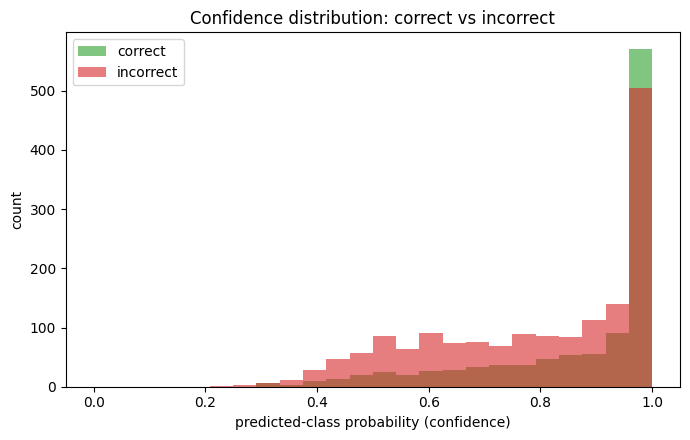

             mean       50%       min  max
correct                                   
False    0.793451  0.846187  0.218180  1.0
True     0.877057  0.967456  0.305751  1.0


In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.linspace(0, 1, 25)
ax.hist(df.loc[df["correct"], "confidence"], bins=bins, alpha=0.6, label="correct", color="#2ca02c")
ax.hist(df.loc[~df["correct"], "confidence"], bins=bins, alpha=0.6, label="incorrect", color="#d62728")
ax.set_xlabel("predicted-class probability (confidence)")
ax.set_ylabel("count")
ax.set_title("Confidence distribution: correct vs incorrect")
ax.legend()
fig.tight_layout()
plt.show()

print(df.groupby("correct")["confidence"].describe()[["mean", "50%", "min", "max"]])

## 6. Does passage length affect accuracy?

Prompts target 40-250 words. If short passages are harder (less stylistic signal to work
with), accuracy should drop at the low end of that range.

                mean  size
len_bucket                
<80         0.341511  1019
80-120      0.369565   598
120-160     0.436073   438
160-200     0.479412   340
200+        0.496711   304


C:\Users\hai\AppData\Local\Temp\ipykernel_15784\3329885534.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  acc_by_len = df.groupby("len_bucket")["correct"].agg(["mean", "size"])


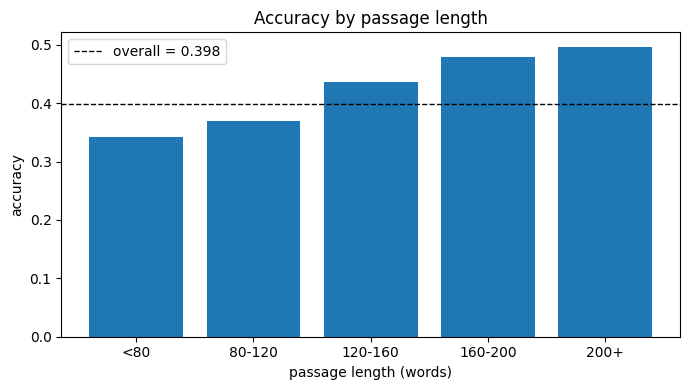

In [7]:
df["len_bucket"] = pd.cut(df["n_words"], bins=[0, 80, 120, 160, 200, 300],
                          labels=["<80", "80-120", "120-160", "160-200", "200+"])
acc_by_len = df.groupby("len_bucket")["correct"].agg(["mean", "size"])
print(acc_by_len)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(acc_by_len.index.astype(str), acc_by_len["mean"], color="#1f77b4")
ax.axhline(plain_acc, color="black", linestyle="--", linewidth=1, label=f"overall = {plain_acc:.3f}")
ax.set_xlabel("passage length (words)")
ax.set_ylabel("accuracy")
ax.set_title("Accuracy by passage length")
ax.legend()
fig.tight_layout()
plt.show()

## 7. Reading actual misclassifications from the worst confusion pairs

Confidence is listed for the *predicted* (wrong) label, so a high number here means the model
was fooled convincingly, not just guessing.

In [8]:
for rate, cnt, true_lbl, pred_lbl in pairs[:3]:
    print(f"\n=== true={true_lbl}  predicted={pred_lbl}  (rate={rate:.2f}, n={cnt}) ===")
    examples = df[(df["true_label"] == true_lbl) & (df["pred_label"] == pred_lbl)].sample(
        min(2, cnt), random_state=0)
    for _, row in examples.iterrows():
        snippet = row["text"][:300].replace("\n", " ")
        print(f"  [confidence={row['confidence']:.2f}] {snippet}...")


=== true=gemini-3.8-flash  predicted=gemini-3.7-flash  (rate=0.31, n=46) ===
  [confidence=0.91] In the early twentieth century, thinkers dreamed of constructing a flawless, universal foundation for mathematics, an ultimate rulebook capable of logically proving every single truth while never generating a contradiction. Kurt Gödel shattered this ambition by demonstrating that truth is fundamenta...
  [confidence=0.50] Far from being a rigid, unyielding relic of youth, the adult brain remains an exquisite, living masterpiece capable of astonishing metamorphosis. Every time you struggle through a challenging concept, immerse yourself in a new discipline, or master an unfamiliar instrument, an invisible revolution u...

=== true=gemini-3.7-flash  predicted=gemini-3.8-flash  (rate=0.27, n=40) ===
  [confidence=0.97] As twilight bruised the desert sky, the caravanserai courtyard exhaled the warmth of baked brick and roasted lamb. Pungent plumes of cardamom, crushed cumin, and star anise min

## Takeaways

- **Same-vendor-family errors are over-represented but not dominant**: 52% of all errors stay
  within the same vendor family (claude/gpt/gemini/glm/qwen/kimi) -- only modestly above what
  18 roughly-equal classes split 6 ways would predict by chance (~also high, families aren't
  equal size, so this alone isn't strong evidence).
- **The real signal is the *named adjacent-version clusters*, and it's large**: of the 1038
  errors whose true label sits in a hard cluster (claude-opus 4-6/4-8/5, gpt-5.6
  luna/sol/terra, gemini flash 3.6/3.7/3.8, glm 5.3/5.3-flash), **42.6%** landed on another
  member of the *same* cluster -- vs ~5.9% expected if errors were spread evenly over the
  other 17 classes. That's a ~7x concentration. The single worst confusion pairs in the whole
  dataset are exactly these clusters (gemini-3.8-flash<->3.7-flash, 3.6<->3.7, the gpt-5.6
  triplet, glm-5.3<->5.3-flash) -- confirms the hypothesis: a meaningful chunk of the error
  budget is genuinely adjacent-version stylistic overlap, not a fixable feature gap.
- **Confidence is reasonably well-calibrated, not confidently-wrong**: median confidence for
  correct predictions is 0.97 vs 0.85 for incorrect ones, and the mean gap (0.88 vs 0.79) is
  real -- the model does know when it's on shakier ground, it's just not shaky enough to flag
  reliably at the per-row level (min confidence on a WRONG prediction was 0.22, but also 0.91
  and 0.97 on two of the worst-cluster examples read above -- so some errors genuinely fool it).
- **Passage length matters a lot**: accuracy climbs steadily from 0.34 (<80 words) to 0.50
  (200+ words) -- the shortest passages (38% of the dataset) are both the hardest AND the most
  common length bucket. This is a concrete, actionable lever the cluster-confusion finding
  isn't: short passages may be worth a dedicated handling path (e.g. weighting, or a feature
  set less dependent on having enough tokens to establish a stylistic fingerprint) rather than
  accepting them as a hard floor the way adjacent-version confusion looks like one.
- **Net read**: part of the ~0.60 error rate is a real ceiling (same-family adjacent-version
  overlap), but part is NOT a ceiling -- the strong length-accuracy relationship says there is
  recoverable accuracy specifically on short passages worth pursuing before assuming we're
  near the limit.